Imports et configuration

In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("prasunroy/natural-images")

print("Path to dataset files:", path)

100%|██████████| 342M/342M [00:04<00:00, 77.9MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/prasunroy/natural-images/versions/1


In [2]:
import os, time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import kagglehub

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Téléchargement du dataset
path = kagglehub.dataset_download("prasunroy/natural-images")
print("Path to dataset files:", path)

# Recherche automatique du dossier qui contient les 8 classes
# (le dataset contient aussi data/natural_images avec 6 classes : on l'ignore)
DATA_DIR = None
for racine, dossiers, _ in os.walk(path):
    if "airplane" in dossiers and "car" in dossiers:
        DATA_DIR = racine
        break

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

print("Dossier de travail :", os.getcwd())
print("TensorFlow :", tf.__version__)
print("DATA_DIR :", DATA_DIR)
print("Dossier trouvé :", DATA_DIR is not None and os.path.exists(DATA_DIR))
print("Classes :", sorted(os.listdir(DATA_DIR)))

Path to dataset files: /root/.cache/kagglehub/datasets/prasunroy/natural-images/versions/1
Dossier de travail : /content
TensorFlow : 2.21.0
DATA_DIR : /root/.cache/kagglehub/datasets/prasunroy/natural-images/versions/1/natural_images
Dossier trouvé : True
Classes : ['airplane', 'car', 'cat', 'dog', 'flower', 'fruit', 'motorbike', 'person']


Exploration du dataset

Nombre total d'images : 6899
Nombre de classes : 8
classe
fruit        1000
person        986
car           968
cat           885
flower        843
motorbike     788
airplane      727
dog           702
Name: count, dtype: int64


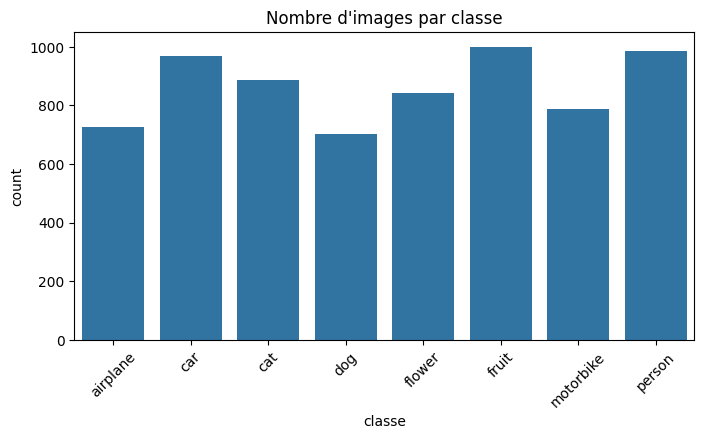

           largeur     hauteur
count   300.000000  300.000000
mean    250.486667  212.460000
std     153.619333  140.849104
min      67.000000   64.000000
25%     100.000000  100.000000
50%     256.000000  178.500000
75%     302.000000  267.750000
max    1111.000000  883.000000


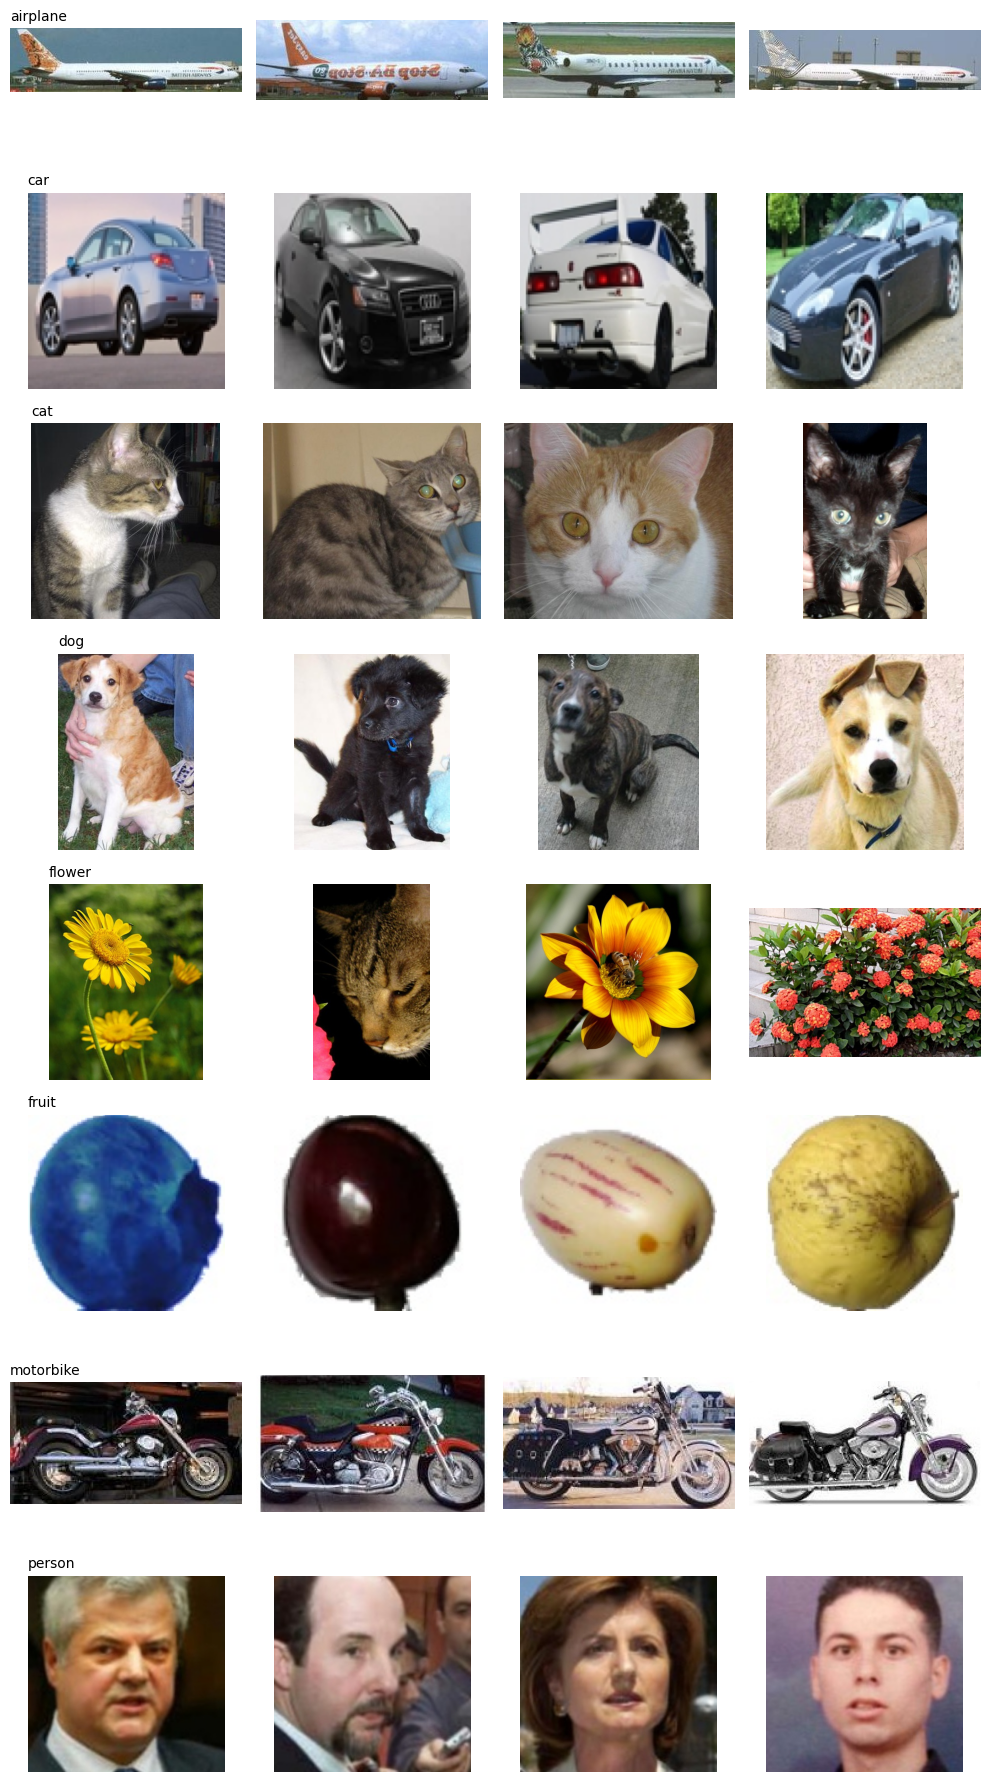

In [3]:
class_names = sorted([d for d in os.listdir(DATA_DIR) if os.path.isdir(os.path.join(DATA_DIR, d))])
num_classes = len(class_names)

filepaths, labels = [], []
for idx, c in enumerate(class_names):
    for f in os.listdir(os.path.join(DATA_DIR, c)):
        if f.lower().endswith((".jpg", ".jpeg", ".png")):
            filepaths.append(os.path.join(DATA_DIR, c, f))
            labels.append(idx)

df = pd.DataFrame({"path": filepaths, "label": labels})
df["classe"] = df["label"].map(lambda i: class_names[i])

print("Nombre total d'images :", len(df))
print("Nombre de classes :", num_classes)
print(df["classe"].value_counts())

# Répartition des classes
plt.figure(figsize=(8, 4))
sns.countplot(data=df, x="classe", order=class_names)
plt.title("Nombre d'images par classe")
plt.xticks(rotation=45)
plt.show()

# Tailles des images (échantillon de 300 images)
tailles = [Image.open(p).size for p in df["path"].sample(300, random_state=SEED)]
tailles = pd.DataFrame(tailles, columns=["largeur", "hauteur"])
print(tailles.describe())

# Quelques images par classe
fig, axes = plt.subplots(num_classes, 4, figsize=(10, 2.3 * num_classes))
for i, c in enumerate(class_names):
    ex = df[df["classe"] == c].sample(4, random_state=SEED)["path"].values
    for j, p in enumerate(ex):
        axes[i, j].imshow(Image.open(p).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(c, fontsize=10, loc="left")
plt.tight_layout()
plt.show()

Vérification des images

In [4]:
corrompues = []
for p in df["path"]:
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        corrompues.append(p)

print("Images corrompues :", len(corrompues))
if corrompues:
    df = df[~df["path"].isin(corrompues)].reset_index(drop=True)
    print("Nouvelle taille du dataset :", len(df))

Images corrompues : 0


Split train / validation / test (70% / 15% / 15%)

In [5]:
train_df, temp_df = train_test_split(df, test_size=0.30, stratify=df["label"], random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50, stratify=temp_df["label"], random_state=SEED)

train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

print("Train :", len(train_df), "| Val :", len(val_df), "| Test :", len(test_df))

# Vérification de la répartition par classe
rep = pd.DataFrame({
    "train": train_df["classe"].value_counts(),
    "val": val_df["classe"].value_counts(),
    "test": test_df["classe"].value_counts()
})
print(rep)

# Aucune image ne doit être dans deux ensembles à la fois
print("Fuite train/val :", len(set(train_df.path) & set(val_df.path)))
print("Fuite train/test :", len(set(train_df.path) & set(test_df.path)))
print("Fuite val/test :", len(set(val_df.path) & set(test_df.path)))

Train : 4829 | Val : 1035 | Test : 1035
           train  val  test
classe                     
fruit        700  150   150
person       690  148   148
car          678  145   145
cat          619  133   133
flower       590  127   126
motorbike    552  118   118
airplane     509  109   109
dog          491  105   106
Fuite train/val : 0
Fuite train/test : 0
Fuite val/test : 0


Prétraitement (redimensionnement + normalisation) et pipeline tf.data

In [6]:
# Justification de la normalisation : les pixels sont entre 0 et 255.
# On divise par 255 pour obtenir des valeurs dans [0, 1] :
def charger_image(path, label):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img.set_shape([None, None, 3])
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0   # normalisation
    return img, label

def make_ds(dataframe, batch_size=BATCH_SIZE, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((dataframe["path"].values, dataframe["label"].values))
    if shuffle:
        ds = ds.shuffle(len(dataframe), seed=SEED, reshuffle_each_iteration=True)
    ds = ds.map(charger_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

train_ds = make_ds(train_df, shuffle=True)
val_ds = make_ds(val_df)
test_ds = make_ds(test_df)   # pas de shuffle : l'ordre reste celui de test_df

# Vérification de la normalisation
x_batch, y_batch = next(iter(train_ds))
print("Forme d'un batch :", x_batch.shape, y_batch.shape)
print("Min / Max des pixels :", x_batch.numpy().min(), x_batch.numpy().max())

Forme d'un batch : (32, 128, 128, 3) (32,)
Min / Max des pixels : 0.0 1.0


Modèle CNN de base

In [7]:
def build_base_cnn():
    model = keras.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.GlobalAveragePooling2D(),
        layers.Dense(64, activation="relu"),
        layers.Dense(num_classes, activation="softmax")
    ], name="cnn_base")
    return model

model_base = build_base_cnn()
model_base.summary()

Model: "cnn_base"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 102,024 (398.53 KB)

 Trainable params: 102,024 (398.53 KB)

 Non-trainable params: 0 (0.00 B)

Compilation

In [8]:
model_base.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",   # labels entiers (0..7)
    metrics=["accuracy"]
)
print("Modèle compilé.")

Modèle compilé.


Entraînement

In [9]:
histories = {}   # pour comparer les modèles à la fin
temps = {}
params = {}

EPOCHS = 15
debut = time.time()
history_base = model_base.fit(train_ds, validation_data=val_ds, epochs=EPOCHS)
temps["CNN base"] = time.time() - debut
histories["CNN base"] = history_base
params["CNN base"] = model_base.count_params()

print(f"Temps d'entraînement : {temps['CNN base']:.1f} s")

Epoch 1/15
151/151 ━━━━━━━━━━━━━━━━━━━━ 19s 73ms/step - accuracy: 0.3858 - loss: 1.6258 - val_accuracy: 0.5150 - val_loss: 1.3255
Epoch 2/15
151/151 ━━━━━━━━━━━━━━━━━━━━ 7s 26ms/step - accuracy: 0.6345 - loss: 1.0232 - val_accuracy: 0.6667 - val_loss: 0.9540
Epoch 3/15
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.7018 - loss: 0.8281 - val_accuracy: 0.7478 - val_loss: 0.6882
Epoch 4/15
151/151 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.7362 - loss: 0.7418 - val_accuracy: 0.7739 - val_loss: 0.6242
Epoch 5/15
151/151 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.7685 - loss: 0.6385 - val_accuracy: 0.7749 - val_loss: 0.5937
Epoch 6/15
151/151 ━━━━━━━━━━━━━━━━━━━━ 6s 31ms/step - accuracy: 0.7838 - loss: 0.5834 - val_accuracy: 0.7807 - val_loss: 0.6574
Epoch 7/15
151/151 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.7871 - loss: 0.5817 - val_accuracy: 0.7981 - val_loss: 0.5434
Epoch 8/15
151/151 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.8163 - loss: 0.4954 - val_acc

Courbes accuracy et loss

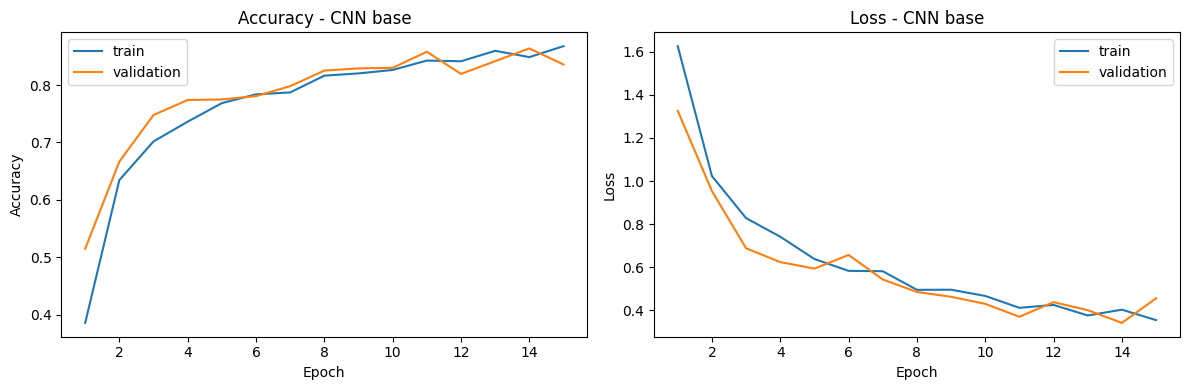

In [10]:
def tracer_courbes(history, titre=""):
    h = history.history
    epochs = range(1, len(h["loss"]) + 1)
    plt.figure(figsize=(12, 4))
    plt.subplot(1, 2, 1)
    plt.plot(epochs, h["accuracy"], label="train")
    plt.plot(epochs, h["val_accuracy"], label="validation")
    plt.title(f"Accuracy {titre}"); plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(epochs, h["loss"], label="train")
    plt.plot(epochs, h["val_loss"], label="validation")
    plt.title(f"Loss {titre}"); plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.legend()
    plt.tight_layout()
    plt.show()

tracer_courbes(history_base, "- CNN base")

Détection du surapprentissage

In [11]:
def analyser_overfitting(history):
    h = history.history
    acc_tr, acc_val = h["accuracy"][-1], h["val_accuracy"][-1]
    loss_tr, loss_val = h["loss"][-1], h["val_loss"][-1]
    meilleure_epoch = int(np.argmin(h["val_loss"])) + 1
    print(f"Accuracy train      : {acc_tr:.4f}")
    print(f"Accuracy validation : {acc_val:.4f}")
    print(f"Écart d'accuracy    : {acc_tr - acc_val:.4f}")
    print(f"Loss train          : {loss_tr:.4f}")
    print(f"Loss validation     : {loss_val:.4f}")
    print(f"Epoch avec la plus petite val_loss : {meilleure_epoch} / {len(h['loss'])}")
    if acc_tr - acc_val > 0.05:
        print("=> Signe de surapprentissage (écart train/val > 5 points).")
    else:
        print("=> Pas de surapprentissage marqué.")
    if meilleure_epoch < len(h["loss"]) - 2:
        print("=> La val_loss remonte avant la fin : l'entraînement est trop long.")

analyser_overfitting(history_base)

Accuracy train      : 0.8677
Accuracy validation : 0.8357
Écart d'accuracy    : 0.0319
Loss train          : 0.3549
Loss validation     : 0.4560
Epoch avec la plus petite val_loss : 14 / 15
=> Pas de surapprentissage marqué.


Accuracy train      : 0.8677
Accuracy validation : 0.8357
Accuracy test       : 0.8531
Loss test           : 0.4575
Écart validation - test : 0.0174
=> Validation et test sont proches : le modèle généralise bien.


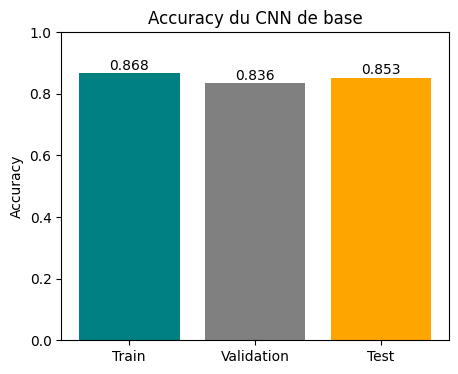

In [12]:
test_loss, test_acc = model_base.evaluate(test_ds, verbose=0)

acc_train = history_base.history["accuracy"][-1]
acc_val = history_base.history["val_accuracy"][-1]

print(f"Accuracy train      : {acc_train:.4f}")
print(f"Accuracy validation : {acc_val:.4f}")
print(f"Accuracy test       : {test_acc:.4f}")
print(f"Loss test           : {test_loss:.4f}")
print(f"Écart validation - test : {abs(acc_val - test_acc):.4f}")

if abs(acc_val - test_acc) < 0.03:
    print("=> Validation et test sont proches : le modèle généralise bien.")
else:
    print("=> Écart important entre validation et test : le réglage sur la validation a pu trop s'adapter.")

# Graphique de comparaison
plt.figure(figsize=(5, 4))
plt.bar(["Train", "Validation", "Test"], [acc_train, acc_val, test_acc], color=["teal", "gray", "orange"])
plt.ylim(0, 1)
plt.ylabel("Accuracy")
plt.title("Accuracy du CNN de base")
for i, v in enumerate([acc_train, acc_val, test_acc]):
    plt.text(i, v + 0.01, f"{v:.3f}", ha="center")
plt.show()

# On garde le résultat pour la comparaison finale
resultats_test = {"CNN base": test_acc}

Modification des hyperparamètres

In [13]:
resultats_lr = {}
for lr in [1e-2, 1e-3, 1e-4]:
    m = build_base_cnn()
    m.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
            loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    h = m.fit(train_ds, validation_data=val_ds, epochs=8, verbose=0)
    resultats_lr[lr] = max(h.history["val_accuracy"])
    print(f"learning rate = {lr} -> meilleure val_accuracy = {resultats_lr[lr]:.4f}")

meilleur_lr = max(resultats_lr, key=resultats_lr.get)
print("Meilleur learning rate :", meilleur_lr)

# Évaluation du modèle de base sur le jeu de test
test_loss, test_acc = model_base.evaluate(test_ds, verbose=0)
print(f"\nCNN base -> Test loss : {test_loss:.4f} | Test accuracy : {test_acc:.4f}")

resultats_test = {"CNN base": test_acc}

learning rate = 0.01 -> meilleure val_accuracy = 0.7981
learning rate = 0.001 -> meilleure val_accuracy = 0.8377
learning rate = 0.0001 -> meilleure val_accuracy = 0.6454
Meilleur learning rate : 0.001

CNN base -> Test loss : 0.4575 | Test accuracy : 0.8531


Amélioration du modèle

Model: "cnn_ameliore"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_15 (Conv2D)              │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_15 (MaxPooling2D) │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 405,384 (1.55 MB)

 Trainable params: 405,384 (1.55 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 13s 40ms/step - accuracy: 0.3023 - loss: 1.7772 - val_accuracy: 0.5256 - val_loss: 1.3270
Epoch 2/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 14s 34ms/step - accuracy: 0.5695 - loss: 1.1715 - val_accuracy: 0.6251 - val_loss: 0.9637
Epoch 3/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.6552 - loss: 0.9631 - val_accuracy: 0.7092 - val_loss: 0.8081
Epoch 4/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.6817 - loss: 0.8862 - val_accuracy: 0.7488 - val_loss: 0.6635
Epoch 5/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 6s 35ms/step - accuracy: 0.7254 - loss: 0.7631 - val_accuracy: 0.7140 - val_loss: 0.7777
Epoch 6/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.7296 - loss: 0.7579 - val_accuracy: 0.7778 - val_loss: 0.5769
Epoch 7/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.7488 - loss: 0.6748 - val_accuracy: 0.7150 - val_loss: 0.7854
Epoch 8/20
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 31ms/step - accuracy: 0.7693 - loss: 0.6490 - val_ac

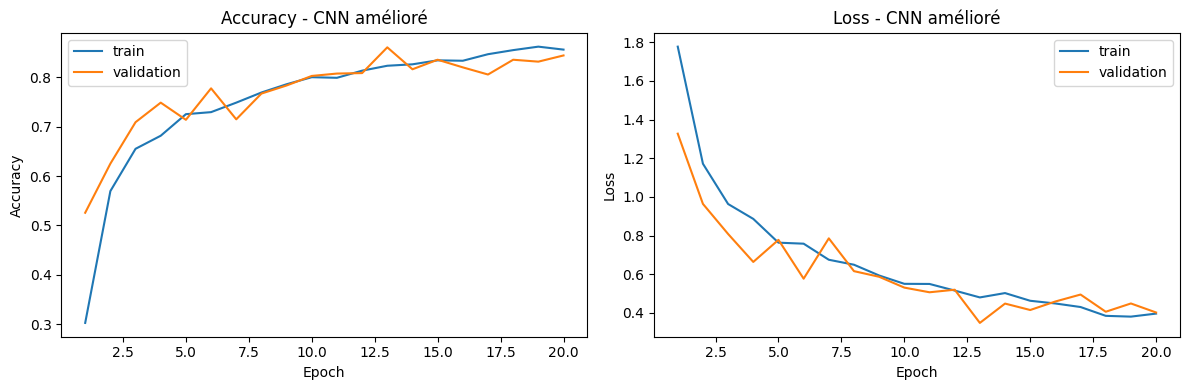

Accuracy train      : 0.8563
Accuracy validation : 0.8444
Écart d'accuracy    : 0.0118
Loss train          : 0.3962
Loss validation     : 0.4020
Epoch avec la plus petite val_loss : 13 / 20
=> Pas de surapprentissage marqué.
=> La val_loss remonte avant la fin : l'entraînement est trop long.
CNN amélioré -> Test accuracy : 0.8715


In [14]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.1),
], name="data_augmentation")   # actif seulement pendant l'entraînement

def build_improved_cnn(dropout=0.3, lr=1e-3):
    model = keras.Sequential([
        layers.Input(shape=IMG_SIZE + (3,)),
        data_augmentation,
        layers.Conv2D(32, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation="relu", padding="same"),
        layers.MaxPooling2D((2, 2)),
        layers.Conv2D(256, (3, 3), activation="relu", padding="same"),   # 4e convolution ajoutée
        layers.MaxPooling2D((2, 2)),
        layers.GlobalAveragePooling2D(),
        layers.Dropout(dropout),
        layers.Dense(64, activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(num_classes, activation="softmax")
    ], name="cnn_ameliore")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model_impr = build_improved_cnn()
model_impr.summary()

debut = time.time()
history_impr = model_impr.fit(train_ds, validation_data=val_ds, epochs=20)
temps["CNN amélioré"] = time.time() - debut
histories["CNN amélioré"] = history_impr
params["CNN amélioré"] = model_impr.count_params()

tracer_courbes(history_impr, "- CNN amélioré")
analyser_overfitting(history_impr)

test_loss, test_acc = model_impr.evaluate(test_ds, verbose=0)
resultats_test["CNN amélioré"] = test_acc
print(f"CNN amélioré -> Test accuracy : {test_acc:.4f}")

Model: "cnn_v2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_16 (Conv2D)              │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_17 (Conv2D)              │ (None, 128, 128, 32)   │         9,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_16 (MaxPooling2D) │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_18 (Conv2D)              │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_19 (Conv2D)              │ (None, 64, 64, 64)     │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_17 (MaxPooling2D) │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_20 (Conv2D)              │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_21 (Conv2D)              │ (None, 32, 32, 128)    │       147,456 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,192,104 (4.55 MB)

 Trainable params: 1,190,184 (4.54 MB)

 Non-trainable params: 1,920 (7.50 KB)

Epoch 1/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 27s 133ms/step - accuracy: 0.5908 - loss: 1.1425 - val_accuracy: 0.1585 - val_loss: 6.0125 - learning_rate: 0.0010
Epoch 2/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 18s 117ms/step - accuracy: 0.7177 - loss: 0.7921 - val_accuracy: 0.2570 - val_loss: 3.6772 - learning_rate: 0.0010
Epoch 3/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 21s 119ms/step - accuracy: 0.7896 - loss: 0.6145 - val_accuracy: 0.5111 - val_loss: 1.8094 - learning_rate: 0.0010
Epoch 4/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 17s 116ms/step - accuracy: 0.8182 - loss: 0.5120 - val_accuracy: 0.3807 - val_loss: 3.9722 - learning_rate: 0.0010
Epoch 5/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 18s 116ms/step - accuracy: 0.8364 - loss: 0.4379 - val_accuracy: 0.6570 - val_loss: 1.1993 - learning_rate: 0.0010
Epoch 6/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 18s 116ms/step - accuracy: 0.8598 - loss: 0.3816 - val_accuracy: 0.6135 - val_loss: 1.6895 - learning_rate: 0.0010
Epoch 7/50
151/151 ━━━━━━━━━━━━━━━━━━━━ 17s 116ms/step - accuracy: 0.8

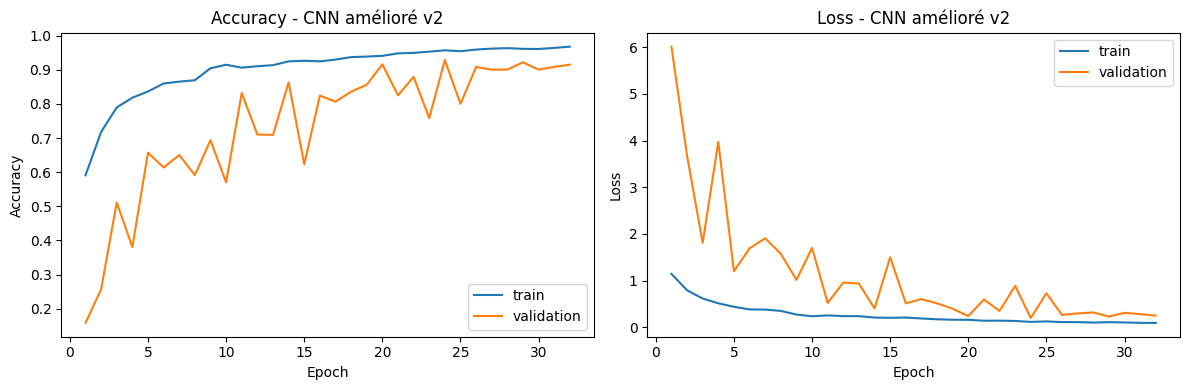

Accuracy train      : 0.9677
Accuracy validation : 0.9150
Écart d'accuracy    : 0.0527
Loss train          : 0.0922
Loss validation     : 0.2482
Epoch avec la plus petite val_loss : 24 / 32
=> Signe de surapprentissage (écart train/val > 5 points).
=> La val_loss remonte avant la fin : l'entraînement est trop long.
CNN amélioré v2 -> Test accuracy : 0.9295


In [15]:
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
], name="data_augmentation")

def bloc_conv(filtres, dropout):
    return [
        layers.Conv2D(filtres, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.Conv2D(filtres, (3, 3), padding="same", use_bias=False),
        layers.BatchNormalization(),
        layers.Activation("relu"),
        layers.MaxPooling2D((2, 2)),
        layers.Dropout(dropout),
    ]

def build_cnn_v2(dropout=0.2, lr=1e-3):
    model = keras.Sequential(
        [layers.Input(shape=IMG_SIZE + (3,)), data_augmentation]
        + bloc_conv(32, dropout)
        + bloc_conv(64, dropout)
        + bloc_conv(128, dropout)
        + bloc_conv(256, dropout)
        + [
            layers.GlobalAveragePooling2D(),
            layers.Dense(64, activation="relu"),
            layers.Dropout(0.3),
            layers.Dense(num_classes, activation="softmax"),
        ],
        name="cnn_v2",
    )
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

model_v2 = build_cnn_v2()
model_v2.summary()

callbacks = [
    keras.callbacks.EarlyStopping(monitor="val_loss", patience=8, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5, verbose=1),
]

debut = time.time()
history_v2 = model_v2.fit(train_ds, validation_data=val_ds, epochs=50, callbacks=callbacks)
temps["CNN amélioré v2"] = time.time() - debut
histories["CNN amélioré v2"] = history_v2
params["CNN amélioré v2"] = model_v2.count_params()

tracer_courbes(history_v2, "- CNN amélioré v2")
analyser_overfitting(history_v2)

test_loss, test_acc = model_v2.evaluate(test_ds, verbose=0)
resultats_test["CNN amélioré v2"] = test_acc
print(f"CNN amélioré v2 -> Test accuracy : {test_acc:.4f}")

Tuning d'hyperparamètres

In [16]:
grille = [(0.2, 1e-3), (0.3, 5e-4), (0.5, 1e-3), (0.3, 1e-3)]
res_tuning = []
for dp, lr in grille:
    m = build_improved_cnn(dropout=dp, lr=lr)
    h = m.fit(train_ds, validation_data=val_ds, epochs=10, verbose=0)
    best = max(h.history["val_accuracy"])
    res_tuning.append({"dropout": dp, "learning_rate": lr, "meilleure_val_acc": round(best, 4)})
    print(f"dropout={dp} | lr={lr} -> val_acc = {best:.4f}")

tuning_df = pd.DataFrame(res_tuning).sort_values("meilleure_val_acc", ascending=False)
print("\nClassement :")
print(tuning_df)

best_cfg = tuning_df.iloc[0]
print("\nMeilleure configuration :", dict(best_cfg))

dropout=0.2 | lr=0.001 -> val_acc = 0.8010
dropout=0.3 | lr=0.0005 -> val_acc = 0.7981
dropout=0.5 | lr=0.001 -> val_acc = 0.8126
dropout=0.3 | lr=0.001 -> val_acc = 0.8068

Classement :
   dropout  learning_rate  meilleure_val_acc
2      0.5         0.0010             0.8126
3      0.3         0.0010             0.8068
0      0.2         0.0010             0.8010
1      0.3         0.0005             0.7981

Meilleure configuration : {'dropout': np.float64(0.5), 'learning_rate': np.float64(0.001), 'meilleure_val_acc': np.float64(0.8126)}


In [17]:
grille = [(0.1, 1e-3), (0.2, 1e-3), (0.3, 1e-3), (0.2, 5e-4)]
res_tuning = []
for dp, lr in grille:
    m = build_cnn_v2(dropout=dp, lr=lr)
    cb = [keras.callbacks.EarlyStopping(monitor="val_loss", patience=6, restore_best_weights=True)]
    h = m.fit(train_ds, validation_data=val_ds, epochs=25, callbacks=cb, verbose=0)
    best = max(h.history["val_accuracy"])
    res_tuning.append({"dropout": dp, "learning_rate": lr, "meilleure_val_acc": round(best, 4)})
    print(f"dropout={dp} | lr={lr} -> val_acc = {best:.4f}")

tuning_df = pd.DataFrame(res_tuning).sort_values("meilleure_val_acc", ascending=False)
print("\nClassement :")
print(tuning_df)
print("\nMeilleure configuration :")
print(tuning_df.iloc[0])

dropout=0.1 | lr=0.001 -> val_acc = 0.8116
dropout=0.2 | lr=0.001 -> val_acc = 0.7594
dropout=0.3 | lr=0.001 -> val_acc = 0.8502
dropout=0.2 | lr=0.0005 -> val_acc = 0.8763

Classement :
   dropout  learning_rate  meilleure_val_acc
3      0.2         0.0005             0.8763
2      0.3         0.0010             0.8502
0      0.1         0.0010             0.8116
1      0.2         0.0010             0.7594

Meilleure configuration :
dropout              0.2000
learning_rate        0.0005
meilleure_val_acc    0.8763
Name: 3, dtype: float64


Transfer learning avec MobileNetV2

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "transfer_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_14     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_35 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_28 (Dense)                │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_29 (Dense)                │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,488 (8.93 MB)

 Trainable params: 82,504 (322.28 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 11s 44ms/step - accuracy: 0.9416 - loss: 0.2029 - val_accuracy: 0.9942 - val_loss: 0.0157
Epoch 2/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.9925 - loss: 0.0237 - val_accuracy: 0.9971 - val_loss: 0.0073
Epoch 3/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.9930 - loss: 0.0203 - val_accuracy: 0.9971 - val_loss: 0.0099
Epoch 4/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 35ms/step - accuracy: 0.9936 - loss: 0.0215 - val_accuracy: 0.9990 - val_loss: 0.0046
Epoch 5/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9957 - loss: 0.0144 - val_accuracy: 0.9971 - val_loss: 0.0081
Epoch 6/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.9936 - loss: 0.0203 - val_accuracy: 0.9961 - val_loss: 0.0144
Epoch 7/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9965 - loss: 0.0112 - val_accuracy: 0.9971 - val_loss: 0.0110
Epoch 8/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.9946 - loss: 0.0172 - val_acc

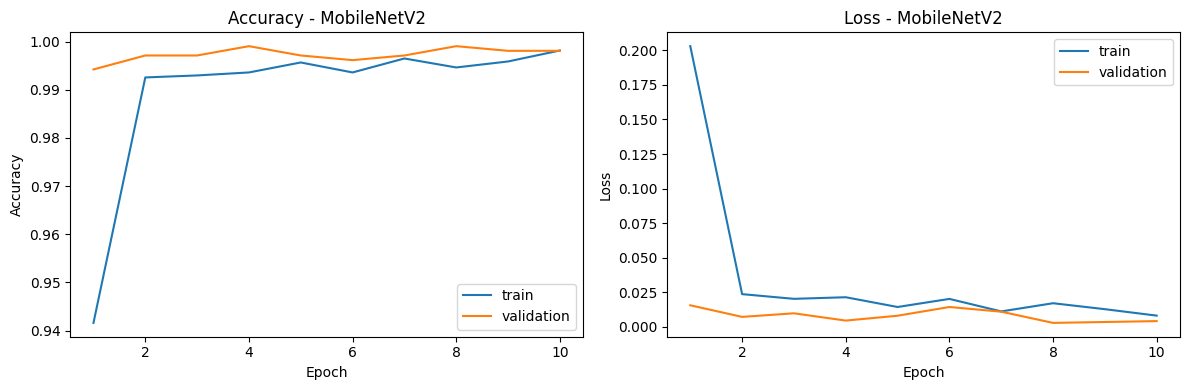

Accuracy train      : 0.9981
Accuracy validation : 0.9981
Écart d'accuracy    : 0.0001
Loss train          : 0.0082
Loss validation     : 0.0042
Epoch avec la plus petite val_loss : 8 / 10
=> Pas de surapprentissage marqué.
MobileNetV2 -> Test accuracy : 0.9961


In [18]:
base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet"
)
base_model.trainable = False   # on gèle le réseau pré-entraîné

model_tl = keras.Sequential([
    layers.Input(shape=IMG_SIZE + (3,)),
    data_augmentation,
    layers.Rescaling(2.0, offset=-1.0),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(64, activation="relu"),
    layers.Dense(num_classes, activation="softmax")
], name="transfer_mobilenetv2")

model_tl.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_tl.summary()

debut = time.time()
history_tl = model_tl.fit(train_ds, validation_data=val_ds, epochs=10)
temps["MobileNetV2 (TL)"] = time.time() - debut
histories["MobileNetV2 (TL)"] = history_tl
params["MobileNetV2 (TL)"] = model_tl.count_params()

tracer_courbes(history_tl, "- MobileNetV2")
analyser_overfitting(history_tl)

test_loss, test_acc = model_tl.evaluate(test_ds, verbose=0)
resultats_test["MobileNetV2 (TL)"] = test_acc
print(f"MobileNetV2 -> Test accuracy : {test_acc:.4f}")

Model: "transfer_mobilenetv2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_19 (InputLayer)     │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_128            │ (None, 4, 4, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_15     │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_36 (Dropout)            │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_30 (Dense)                │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_31 (Dense)                │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,488 (8.93 MB)

 Trainable params: 82,504 (322.28 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 11s 45ms/step - accuracy: 0.9507 - loss: 0.1703 - val_accuracy: 0.9942 - val_loss: 0.0190
Epoch 2/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9901 - loss: 0.0351 - val_accuracy: 0.9952 - val_loss: 0.0147
Epoch 3/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 6s 36ms/step - accuracy: 0.9940 - loss: 0.0180 - val_accuracy: 0.9961 - val_loss: 0.0123
Epoch 4/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.9952 - loss: 0.0142 - val_accuracy: 0.9981 - val_loss: 0.0137
Epoch 5/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9954 - loss: 0.0148 - val_accuracy: 0.9952 - val_loss: 0.0132
Epoch 6/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 36ms/step - accuracy: 0.9950 - loss: 0.0147 - val_accuracy: 0.9961 - val_loss: 0.0083
Epoch 7/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9971 - loss: 0.0072 - val_accuracy: 0.9971 - val_loss: 0.0068
Epoch 8/10
151/151 ━━━━━━━━━━━━━━━━━━━━ 5s 33ms/step - accuracy: 0.9948 - loss: 0.0167 - val_acc

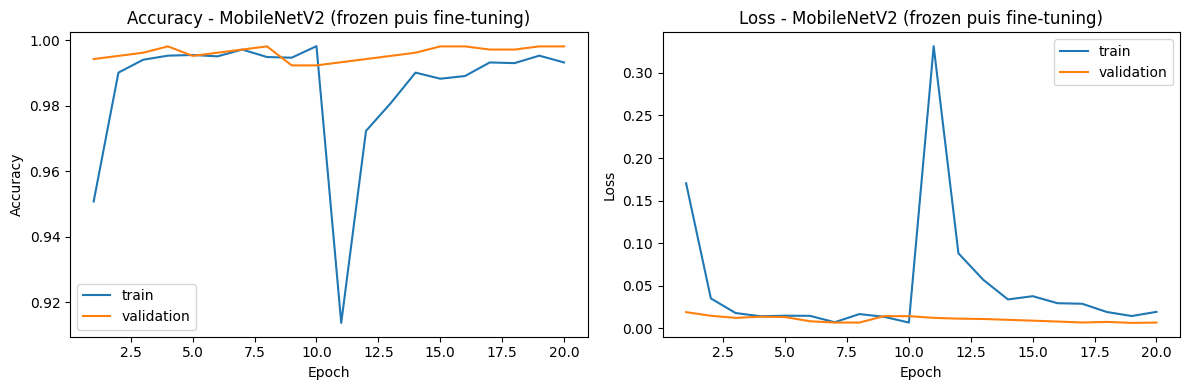

Accuracy train      : 0.9932
Accuracy validation : 0.9981
Écart d'accuracy    : -0.0049
Loss train          : 0.0194
Loss validation     : 0.0068
Epoch avec la plus petite val_loss : 19 / 20
=> Pas de surapprentissage marqué.
MobileNetV2 -> Test accuracy : 0.9961


In [19]:
base_model = keras.applications.MobileNetV2(
    input_shape=IMG_SIZE + (3,), include_top=False, weights="imagenet"
)
base_model.trainable = False

inputs = keras.Input(shape=IMG_SIZE + (3,))
x = data_augmentation(inputs)
x = layers.Rescaling(2.0, offset=-1.0)(x)        # [0,1] -> [-1,1] attendu par MobileNetV2
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(64, activation="relu")(x)
outputs = layers.Dense(num_classes, activation="softmax")(x)
model_tl = keras.Model(inputs, outputs, name="transfer_mobilenetv2")

model_tl.compile(optimizer=keras.optimizers.Adam(1e-3),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model_tl.summary()

debut = time.time()
h1 = model_tl.fit(train_ds, validation_data=val_ds, epochs=10)

# Fine-tuning
base_model.trainable = True
for couche in base_model.layers[:-30]:
    couche.trainable = False

model_tl.compile(optimizer=keras.optimizers.Adam(1e-5),
                 loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model_tl.fit(train_ds, validation_data=val_ds, epochs=10)
temps["MobileNetV2 (TL)"] = time.time() - debut

# On fusionne les deux historiques pour tracer les courbes
class HistoriqueFusionne:
    pass
history_tl = HistoriqueFusionne()
history_tl.history = {k: h1.history[k] + h2.history[k] for k in h1.history}

histories["MobileNetV2 (TL)"] = history_tl
params["MobileNetV2 (TL)"] = model_tl.count_params()

tracer_courbes(history_tl, "- MobileNetV2 (frozen puis fine-tuning)")
analyser_overfitting(history_tl)

test_loss, test_acc = model_tl.evaluate(test_ds, verbose=0)
resultats_test["MobileNetV2 (TL)"] = test_acc
print(f"MobileNetV2 -> Test accuracy : {test_acc:.4f}")

Comparaison des architectures

                  Paramètres totaux  Paramètres entraînables  \
CNN base                     102024                   102024   
CNN amélioré                 405384                   405384   
MobileNetV2 (TL)            2340488                  1608904   

                  Temps d'entraînement (s)  Val accuracy (finale)  \
CNN base                              86.7                 0.8357   
CNN amélioré                         118.2                 0.8444   
MobileNetV2 (TL)                     152.4                 0.9981   

                  Test accuracy  
CNN base                 0.8531  
CNN amélioré             0.8715  
MobileNetV2 (TL)         0.9961  


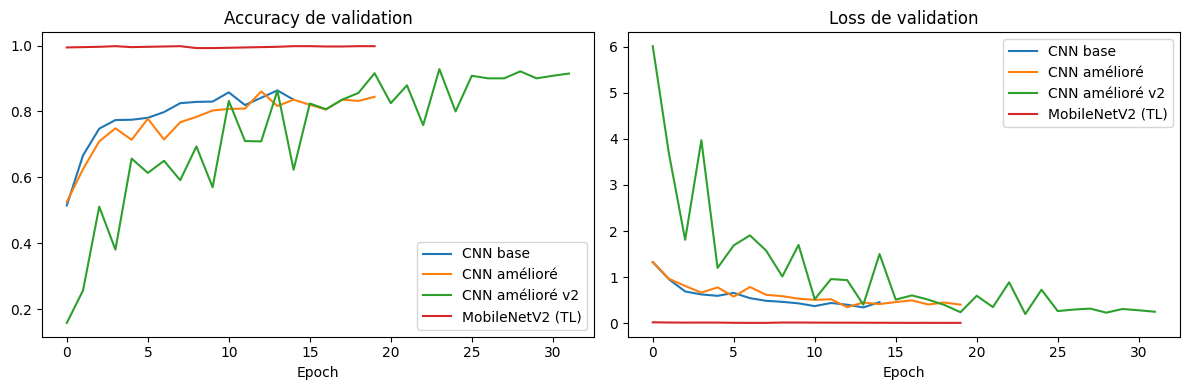

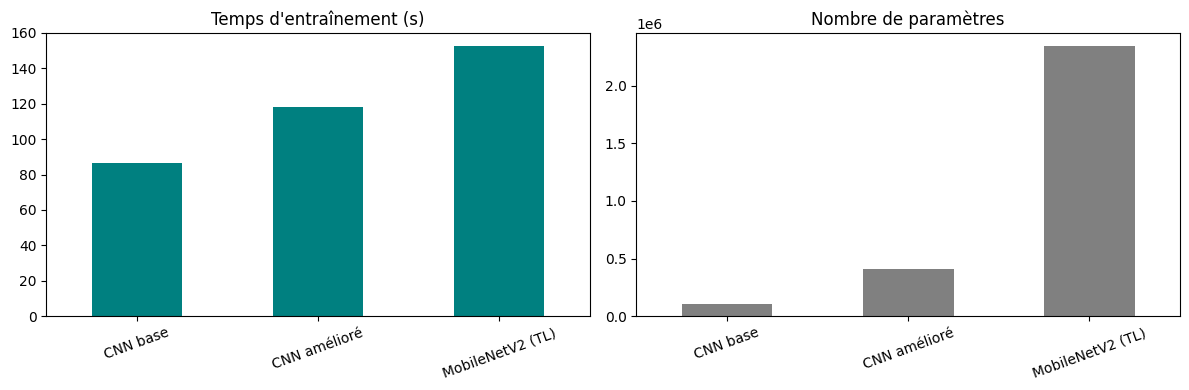

In [20]:
modeles = {"CNN base": model_base, "CNN amélioré": model_impr, "MobileNetV2 (TL)": model_tl}

tableau = pd.DataFrame({
    "Paramètres totaux": {k: params[k] for k in modeles},
    "Paramètres entraînables": {k: int(np.sum([np.prod(w.shape) for w in m.trainable_weights])) for k, m in modeles.items()},
    "Temps d'entraînement (s)": {k: round(temps[k], 1) for k in modeles},
    "Val accuracy (finale)": {k: round(histories[k].history["val_accuracy"][-1], 4) for k in modeles},
    "Test accuracy": {k: round(resultats_test[k], 4) for k in modeles},
})
print(tableau)

# Courbes de validation comparées
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
for k, h in histories.items():
    plt.plot(h.history["val_accuracy"], label=k)
plt.title("Accuracy de validation"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
for k, h in histories.items():
    plt.plot(h.history["val_loss"], label=k)
plt.title("Loss de validation"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout()
plt.show()

# Histogrammes : temps et nombre de paramètres
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tableau["Temps d'entraînement (s)"].plot(kind="bar", ax=ax[0], color="teal", title="Temps d'entraînement (s)")
tableau["Paramètres totaux"].plot(kind="bar", ax=ax[1], color="gray", title="Nombre de paramètres")
for a in ax: a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

                  Paramètres totaux  Paramètres entraînables  \
CNN base                     102024                   102024   
CNN amélioré                 405384                   405384   
CNN amélioré v2             1192104                  1190184   
MobileNetV2 (TL)            2340488                  1608904   

                  Temps d'entraînement (s)  Val accuracy (finale)  \
CNN base                              86.7                 0.8357   
CNN amélioré                         118.2                 0.8444   
CNN amélioré v2                      587.1                 0.9150   
MobileNetV2 (TL)                     152.4                 0.9981   

                  Test accuracy  
CNN base                 0.8531  
CNN amélioré             0.8715  
CNN amélioré v2          0.9295  
MobileNetV2 (TL)         0.9961  


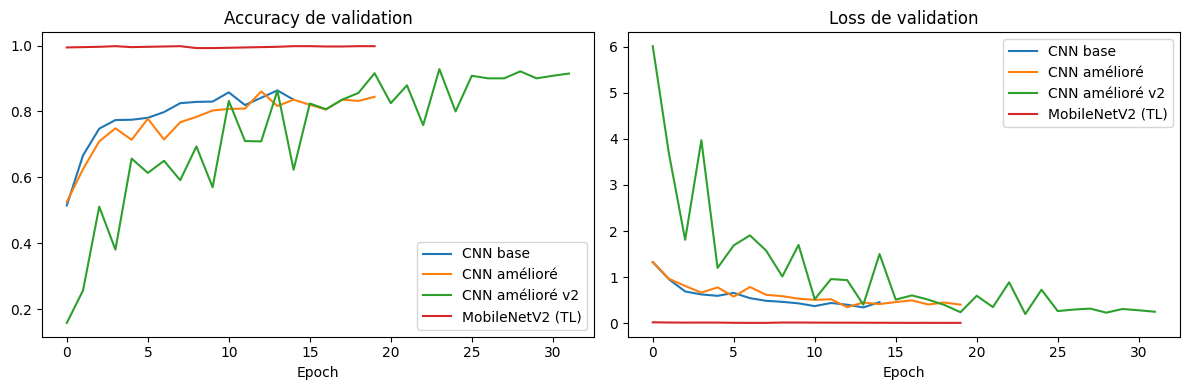

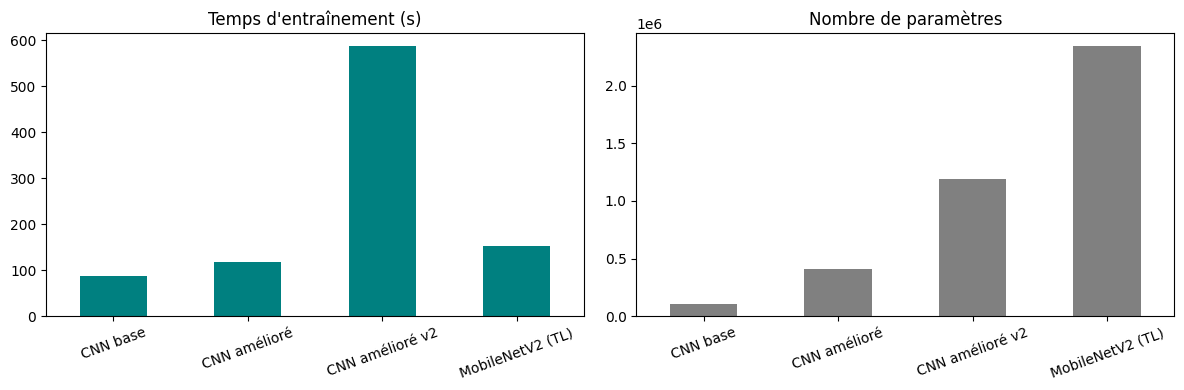

In [21]:
modeles = {
    "CNN base": model_base,
    "CNN amélioré": model_impr,
    "CNN amélioré v2": model_v2,
    "MobileNetV2 (TL)": model_tl,
}

tableau = pd.DataFrame({
    "Paramètres totaux": {k: params[k] for k in modeles},
    "Paramètres entraînables": {k: int(np.sum([np.prod(w.shape) for w in m.trainable_weights])) for k, m in modeles.items()},
    "Temps d'entraînement (s)": {k: round(temps[k], 1) for k in modeles},
    "Val accuracy (finale)": {k: round(histories[k].history["val_accuracy"][-1], 4) for k in modeles},
    "Test accuracy": {k: round(resultats_test[k], 4) for k in modeles},
})
print(tableau)

plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
for k, h in histories.items():
    plt.plot(h.history["val_accuracy"], label=k)
plt.title("Accuracy de validation"); plt.xlabel("Epoch"); plt.legend()
plt.subplot(1, 2, 2)
for k, h in histories.items():
    plt.plot(h.history["val_loss"], label=k)
plt.title("Loss de validation"); plt.xlabel("Epoch"); plt.legend()
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
tableau["Temps d'entraînement (s)"].plot(kind="bar", ax=ax[0], color="teal", title="Temps d'entraînement (s)")
tableau["Paramètres totaux"].plot(kind="bar", ax=ax[1], color="gray", title="Nombre de paramètres")
for a in ax: a.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

Erreurs par classe

Meilleur modèle sur le test : MobileNetV2 (TL)


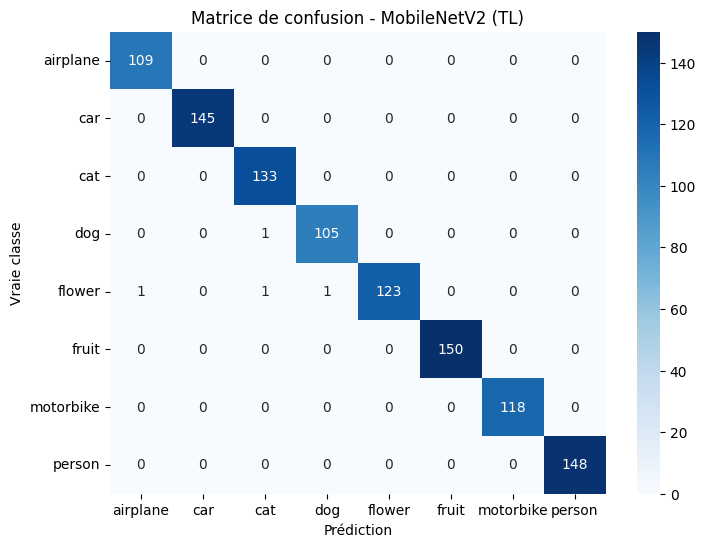

              precision    recall  f1-score   support

    airplane       0.99      1.00      1.00       109
         car       1.00      1.00      1.00       145
         cat       0.99      1.00      0.99       133
         dog       0.99      0.99      0.99       106
      flower       1.00      0.98      0.99       126
       fruit       1.00      1.00      1.00       150
   motorbike       1.00      1.00      1.00       118
      person       1.00      1.00      1.00       148

    accuracy                           1.00      1035
   macro avg       1.00      1.00      1.00      1035
weighted avg       1.00      1.00      1.00      1035

flower       0.024
dog          0.009
car          0.000
airplane     0.000
cat          0.000
fruit        0.000
motorbike    0.000
person       0.000
dtype: float64


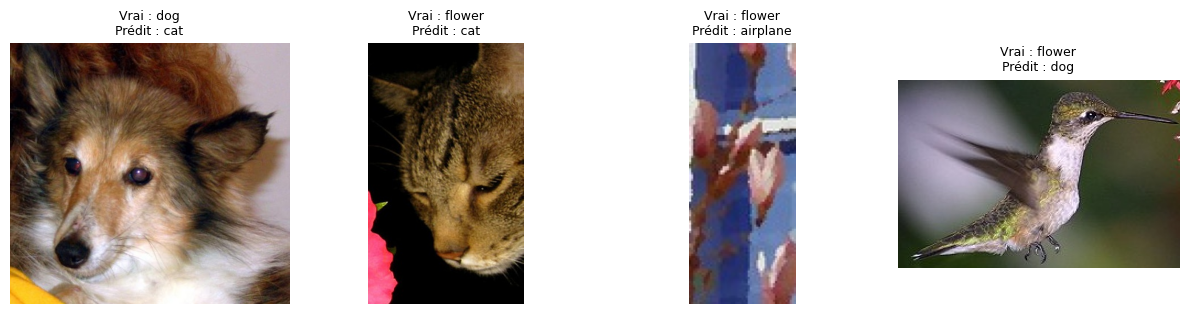

In [22]:
nom_meilleur = max(resultats_test, key=resultats_test.get)
meilleur_modele = modeles[nom_meilleur]
print("Meilleur modèle sur le test :", nom_meilleur)

y_true = test_df["label"].values
y_pred = np.argmax(meilleur_modele.predict(test_ds, verbose=0), axis=1)

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédiction"); plt.ylabel("Vraie classe")
plt.title(f"Matrice de confusion - {nom_meilleur}")
plt.show()

print(classification_report(y_true, y_pred, target_names=class_names))

# Erreurs par classe
erreurs_classe = 1 - cm.diagonal() / cm.sum(axis=1)
print(pd.Series(erreurs_classe, index=class_names).round(3).sort_values(ascending=False))

# Quelques images mal classées
idx_err = np.where(y_true != y_pred)[0][:8]
plt.figure(figsize=(12, 6))
for i, k in enumerate(idx_err):
    plt.subplot(2, 4, i + 1)
    plt.imshow(Image.open(test_df.loc[k, "path"]).convert("RGB"))
    plt.title(f"Vrai : {class_names[y_true[k]]}\nPrédit : {class_names[y_pred[k]]}", fontsize=9)
    plt.axis("off")
plt.tight_layout()
plt.show()

Prédiction sur de nouvelles images

Fichier : /root/.cache/kagglehub/datasets/prasunroy/natural-images/versions/1/natural_images/fruit/fruit_0787.jpg


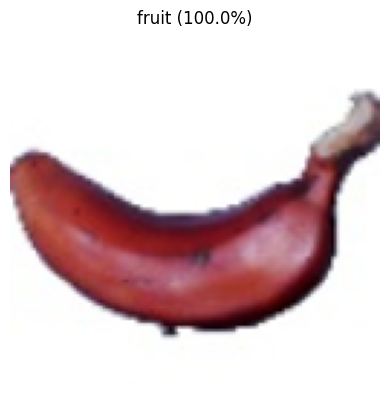

fruit        : 100.00%
dog          : 0.00%
airplane     : 0.00%
Fichier : /root/.cache/kagglehub/datasets/prasunroy/natural-images/versions/1/natural_images/fruit/fruit_0185.jpg


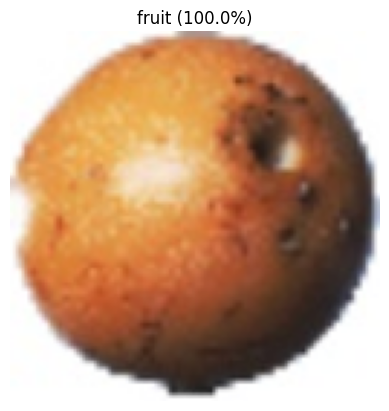

fruit        : 100.00%
dog          : 0.00%
flower       : 0.00%
Fichier : /root/.cache/kagglehub/datasets/prasunroy/natural-images/versions/1/natural_images/cat/cat_0204.jpg


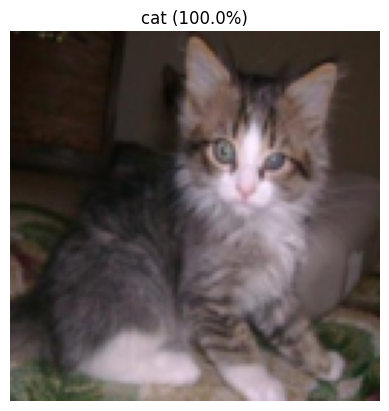

cat          : 100.00%
dog          : 0.00%
flower       : 0.00%


In [23]:
def predire_image(chemin, modele=meilleur_modele):
    img = Image.open(chemin).convert("RGB").resize(IMG_SIZE)
    x = np.array(img, dtype="float32") / 255.0      # même normalisation qu'à l'entraînement
    x = np.expand_dims(x, axis=0)
    probas = modele.predict(x, verbose=0)[0]
    top = np.argsort(probas)[::-1][:3]
    plt.imshow(img); plt.axis("off")
    plt.title(f"{class_names[top[0]]} ({probas[top[0]]*100:.1f}%)")
    plt.show()
    for i in top:
        print(f"{class_names[i]:<12} : {probas[i]*100:.2f}%")

# Option A : une image de ton choix (mets le chemin de ta photo)
# predire_image("mon_image.jpg")

# Option B : upload dans Google Colab
# from google.colab import files
# up = files.upload()
# for nom in up.keys():
#     predire_image(nom)

# Option C : démonstration avec quelques images du jeu de test
for p in test_df.sample(3, random_state=1)["path"]:
    print("Fichier :", p)
    predire_image(p)

In [24]:
import os, json, shutil

os.makedirs("saved_models", exist_ok=True)

modeles = {
    "CNN base": model_base,
    "CNN amélioré": model_impr,
    "MobileNetV2 (TL)": model_tl,
}
fichiers = {
    "CNN base": "cnn_base",
    "CNN amélioré": "cnn_ameliore",
    "MobileNetV2 (TL)": "mobilenetv2_tl",
}

y_true = test_df["label"].values
info = {"class_names": class_names, "models": {}}

for nom, m in modeles.items():
    m.save(f"saved_models/{fichiers[nom]}.keras")
    probas = m.predict(test_ds, verbose=0)
    y_pred = np.argmax(probas, axis=1)
    test_loss, test_acc = m.evaluate(test_ds, verbose=0)
    info["models"][nom] = {
        "params": int(params[nom]),
        "trainable_params": int(np.sum([np.prod(w.shape) for w in m.trainable_weights])),
        "train_time": float(temps[nom]),
        "test_acc": float(test_acc),
        "test_loss": float(test_loss),
        "history": {k: [float(v) for v in vals] for k, vals in histories[nom].history.items()},
        "confusion_matrix": confusion_matrix(y_true, y_pred).tolist(),
        "report": classification_report(y_true, y_pred, target_names=class_names, output_dict=True),
    }

with open("saved_models/info.json", "w", encoding="utf-8") as f:
    json.dump(info, f, ensure_ascii=False, indent=2)

shutil.make_archive("saved_models", "zip", "saved_models")

from google.colab import files
files.download("saved_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>